# Notebook 05: Comparative Analysis of Purely Geometric Losses, Layerwise Curvature Profiles, and Parameter Geometry

## Research Objective
We synthesize our investigation by comparing **three purely geometric training objectives** against the **standard Cross-Entropy baseline** on the `[2 -> 5 -> 10 -> 15 -> 10 -> 2]` MLP:

1. **Cross-Entropy Baseline**: $\mathcal{L}_{\text{CE}}(\theta) = -\frac{1}{N}\sum_n \log p_\theta(y_n | x_n)$ (coordinate/logit supervision).
2. **Gaussian Curvature Margin Loss (2nd-Fundamental / Riemann Invariant)**:
   Places Class $0$ in negative Gaussian curvature ($K^{(5)}(x) \le -\tau$) and Class $1$ in positive Gaussian curvature ($K^{(5)}(x) \ge +\tau$).
3. **Riemannian Volume-Element Contrastive Loss (Metric Determinant Invariant)**:
   Places Class $0$ in volume-contracting regions ($\log\sqrt{\det g^{(5)}(x)} \le -\tau$) and Class $1$ in volume-expanding regions ($\log\sqrt{\det g^{(5)}(x)} \ge +\tau$).
4. **Metric Anisotropy / Polarization Loss (Metric Ratio Invariant)**:
   Separates classes by directional metric stretching $\log(g^{(5)}_{11}(x) / g^{(5)}_{22}(x)) \lessgtr \pm \tau$.

Finally, we analyze the **back-reaction on the Parameter Manifold ($\Theta$)**: how training with purely geometric objectives on the data manifold reshapes the layerwise curvature profile $K^{(1 \dots 5)}$ and the $422 \times 422$ Parameter Manifold metric spectrum $G^{\Theta}_{\mu\nu}(\theta) = \mathbb{E}_x[(J_\theta z)^T (J_\theta z)]$.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import numpy as np
import torch
import torch.nn as nn
from torch.func import functional_call, jacrev, vmap
import matplotlib.pyplot as plt

from src.geometry import (
    MoonsMLP,
    get_moons_dataset,
    make_evaluation_grid,
    compute_layer_geometry,
    compute_layer_pullback_metric,
    curvature_margin_loss,
    volume_contrastive_loss,
    anisotropy_margin_loss,
)

X_train, y_train, X_test, y_test = get_moons_dataset(n_train=220, n_test=120, noise=0.10, seed=42)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=26, padding=0.45)

## 1. Training the Four Paradigms (Cross-Entropy vs. Three Purely Geometric Objectives)

In [2]:
# 1. Cross-Entropy Baseline
m_ce = MoonsMLP(activation="tanh", seed=7)
opt_ce = torch.optim.Adam(m_ce.parameters(), lr=0.02)
crit_ce = nn.CrossEntropyLoss()
for _ in range(120):
    opt_ce.zero_grad()
    loss = crit_ce(m_ce(X_train), y_train)
    loss.backward()
    opt_ce.step()
ce_te_acc = (m_ce(X_test).argmax(-1) == y_test).float().mean().item()

# 2. Purely Geometric Curvature Margin Loss (K < 0 vs K > 0)
m_curv = MoonsMLP(activation="tanh", seed=7)
opt_curv = torch.optim.Adam(m_curv.parameters(), lr=0.025)
for _ in range(85):
    opt_curv.zero_grad()
    params = dict(m_curv.named_parameters())
    g5 = compute_layer_geometry(m_curv, X_train, layer_idx=5, metric_mode="graph", params=params)
    loss, _ = curvature_margin_loss(g5["K"], y_train, g5["g"], margin=0.40, lambda_vol=0.02, lambda_iso=0.005, k_clip=10.0)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(m_curv.parameters(), 5.0)
    opt_curv.step()
K_te = compute_layer_geometry(m_curv, X_test, layer_idx=5, metric_mode="graph")["K"]
curv_te_acc = ((K_te > 0.0).long() == y_test).float().mean().item()

# 3. Purely Geometric Volume-Element Contrastive Loss (log sqrt(det g) < 0 vs > 0)
m_vol = MoonsMLP(activation="tanh", seed=7)
opt_vol = torch.optim.Adam(m_vol.parameters(), lr=0.02)
for _ in range(100):
    opt_vol.zero_grad()
    params = dict(m_vol.named_parameters())
    g5 = compute_layer_pullback_metric(m_vol, X_train, layer_idx=5, metric_mode="euclidean", eps=1e-6, params=params)
    loss, _ = volume_contrastive_loss(g5, y_train, margin=0.60)
    loss.backward()
    opt_vol.step()
g5_vol_te = compute_layer_pullback_metric(m_vol, X_test, layer_idx=5, metric_mode="euclidean", eps=1e-6)
log_vol_te = 0.5 * torch.log(torch.clamp(torch.linalg.det(g5_vol_te), min=1e-8))
vol_te_acc = ((log_vol_te > 0.0).long() == y_test).float().mean().item()

# 4. Purely Geometric Metric Anisotropy Loss (log(g11 / g22) < 0 vs > 0)
m_aniso = MoonsMLP(activation="tanh", seed=7)
opt_aniso = torch.optim.Adam(m_aniso.parameters(), lr=0.02)
for _ in range(100):
    opt_aniso.zero_grad()
    params = dict(m_aniso.named_parameters())
    g5 = compute_layer_pullback_metric(m_aniso, X_train, layer_idx=5, metric_mode="graph", params=params)
    loss, _ = anisotropy_margin_loss(g5, y_train, margin=0.45)
    loss.backward()
    opt_aniso.step()
g5_aniso_te = compute_layer_pullback_metric(m_aniso, X_test, layer_idx=5, metric_mode="graph")
aniso_ratio_te = torch.log(g5_aniso_te[:, 0, 0] / g5_aniso_te[:, 1, 1])
aniso_te_acc = ((aniso_ratio_te > 0.0).long() == y_test).float().mean().item()

print(f"{'Training Objective':<44} {'Decision Criterion':<30} {'Test Accuracy':<15}")
print("-" * 90)
print(f"{'1. Cross-Entropy Baseline':<44} {'z_1(x) > z_0(x)':<30} {ce_te_acc*100:6.2f}%")
print(f"{'2. Geometric Curvature Margin Loss':<44} {'K^(5)(x) > 0':<30} {curv_te_acc*100:6.2f}%")
print(f"{'3. Geometric Volume-Element Loss':<44} {'log sqrt(det g^(5)(x)) > 0':<30} {vol_te_acc*100:6.2f}%")
print(f"{'4. Geometric Metric Anisotropy Loss':<44} {'log(g_11^(5) / g_22^(5)) > 0':<30} {aniso_te_acc*100:6.2f}%")

Training Objective                           Decision Criterion             Test Accuracy  
------------------------------------------------------------------------------------------
1. Cross-Entropy Baseline                    z_1(x) > z_0(x)                100.00%
2. Geometric Curvature Margin Loss           K^(5)(x) > 0                    96.67%
3. Geometric Volume-Element Loss             log sqrt(det g^(5)(x)) > 0     100.00%
4. Geometric Metric Anisotropy Loss          log(g_11^(5) / g_22^(5)) > 0   100.00%


## 2. Side-by-Side Comparison of the Learned Geometric Decision Landscapes

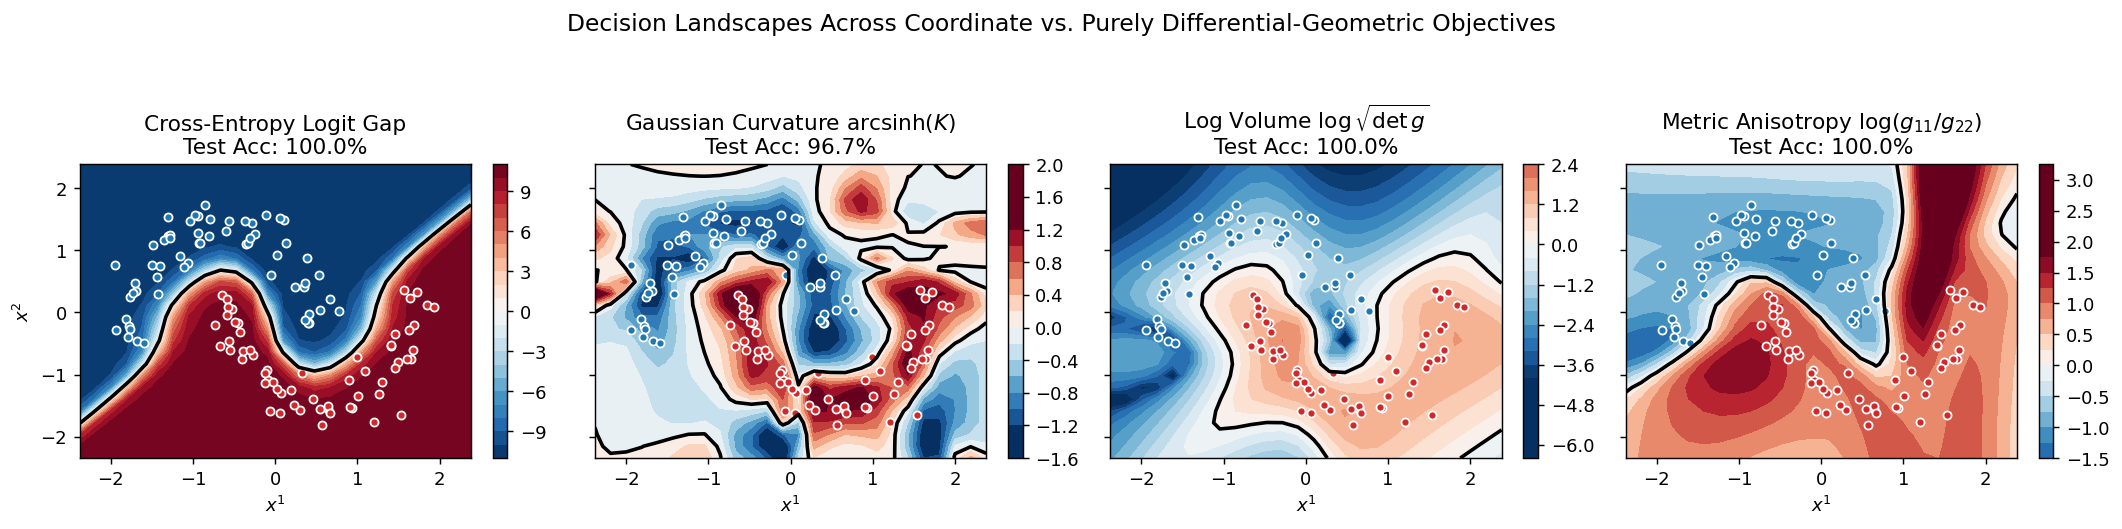

In [3]:
with torch.no_grad():
    f_ce = (m_ce(grid_pts)[:, 1] - m_ce(grid_pts)[:, 0]).numpy().reshape(xx.shape)

f_curv = np.arcsinh(compute_layer_geometry(m_curv, grid_pts, layer_idx=5, metric_mode="graph")["K"].detach().numpy().reshape(xx.shape))

g_vol_grid = compute_layer_pullback_metric(m_vol, grid_pts, layer_idx=5, metric_mode="euclidean", eps=1e-6)
f_vol = (0.5 * torch.log(torch.clamp(torch.linalg.det(g_vol_grid), min=1e-8))).detach().numpy().reshape(xx.shape)

g_aniso_grid = compute_layer_pullback_metric(m_aniso, grid_pts, layer_idx=5, metric_mode="graph")
f_aniso = torch.log(g_aniso_grid[:, 0, 0] / g_aniso_grid[:, 1, 1]).detach().numpy().reshape(xx.shape)

fields = [
    (f_ce, f"Cross-Entropy Logit Gap\nTest Acc: {ce_te_acc*100:.1f}%"),
    (f_curv, f"Gaussian Curvature $\mathrm{{arcsinh}}(K)$\nTest Acc: {curv_te_acc*100:.1f}%"),
    (f_vol, f"Log Volume $\log\sqrt{{\det g}}$\nTest Acc: {vol_te_acc*100:.1f}%"),
    (f_aniso, f"Metric Anisotropy $\log(g_{{11}}/g_{{22}})$\nTest Acc: {aniso_te_acc*100:.1f}%"),
]

fig, axes = plt.subplots(1, 4, figsize=(16.5, 3.9), sharex=True, sharey=True)
for ax, (fld, title) in zip(axes, fields):
    vm = max(np.percentile(np.abs(fld), 95), 0.2)
    im = ax.contourf(xx, yy, fld, levels=22, cmap="RdBu_r", vmin=-vm, vmax=vm)
    ax.contour(xx, yy, fld, levels=[0.0], colors="k", linewidths=2.0)
    ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", edgecolors="w", s=20)
    ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", edgecolors="w", s=20)
    ax.set_title(title)
    ax.set_xlabel("$x^1$")
    plt.colorbar(im, ax=ax, fraction=0.046)
axes[0].set_ylabel("$x^2$")
plt.suptitle("Decision Landscapes Across Coordinate vs. Purely Differential-Geometric Objectives", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

## 3. Layerwise Curvature Profiles & Back-Reaction on the $422 \times 422$ Parameter Manifold Metric
Finally, we compare how the four training objectives distribute curvature across the intermediate hidden layers $\ell \in \{1, 2, 3, 4, 5\}$ and how they shape the eigenspectrum of the $422 \times 422$ Generalized Gauss-Newton / Output Pullback Metric on the parameter manifold $\Theta$:
$$G^\Theta_{\mu\nu}(\theta) = \mathbb{E}_{x \sim \mathcal{D}} \left[ \sum_{a=1}^2 \frac{\partial z^a(x; \theta)}{\partial \theta^\mu} \frac{\partial z^a(x; \theta)}{\partial \theta^\nu} \right]$$

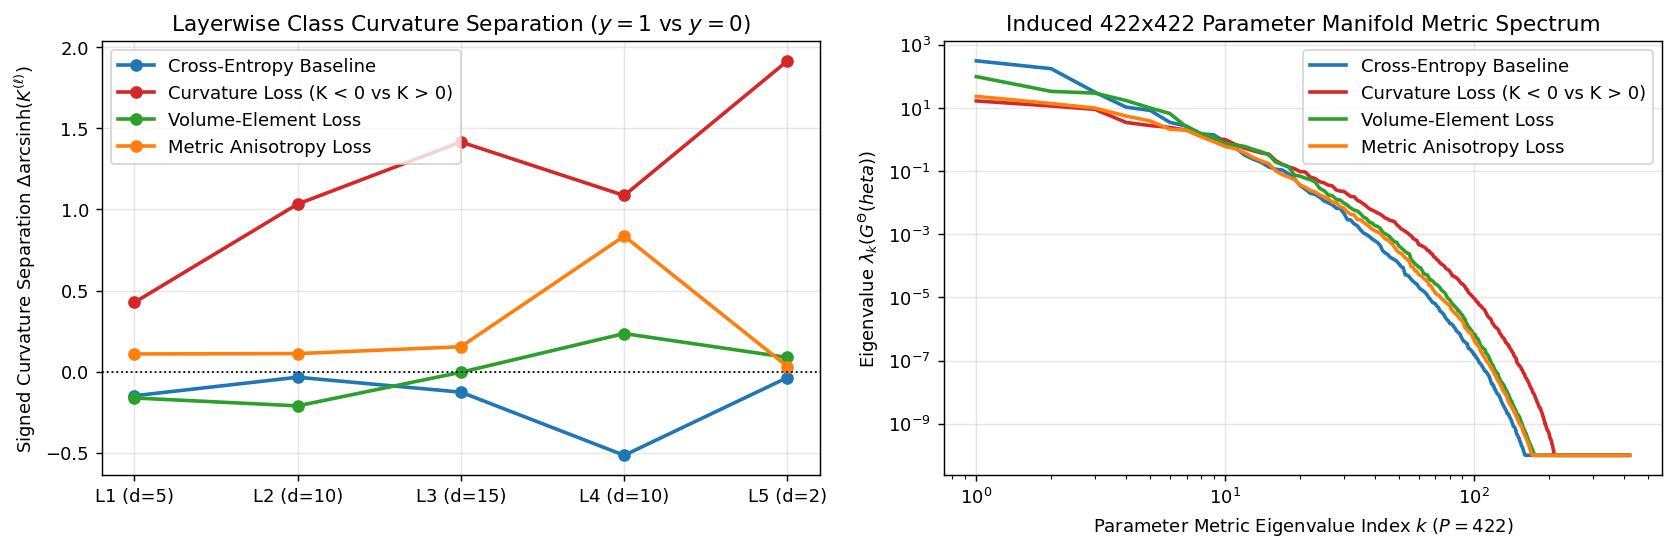

In [4]:
def compute_param_pullback_spectrum(model: MoonsMLP, X: torch.Tensor) -> np.ndarray:
    params = {k: v.detach() for k, v in model.named_parameters()}
    buffers = dict(model.named_buffers())
    keys = list(params.keys())

    def z_fn(p_dict, x_single):
        return functional_call(model, (p_dict, buffers), (x_single.unsqueeze(0),)).squeeze(0)

    J_dict = vmap(jacrev(z_fn, argnums=0), in_dims=(None, 0))(params, X)
    N = X.shape[0]
    J_flat = torch.cat([J_dict[k].reshape(N * 2, -1) for k in keys], dim=-1)
    G_theta = (J_flat.T @ J_flat) / float(N)
    evals = torch.linalg.eigvalsh(G_theta).flip(0).clamp(min=1e-10).detach().numpy()
    return evals

models_dict = {
    "Cross-Entropy Baseline": (m_ce, "#1f77b4"),
    "Curvature Loss (K < 0 vs K > 0)": (m_curv, "#d62728"),
    "Volume-Element Loss": (m_vol, "#2ca02c"),
    "Metric Anisotropy Loss": (m_aniso, "#ff7f0e"),
}

layers_list = [1, 2, 3, 4, 5]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

for label, (mdl, col) in models_dict.items():
    # Layerwise signed curvature gap E[K|y=1] - E[K|y=0]
    k_gaps = []
    for l_idx in layers_list:
        mode = "graph" if l_idx == 5 else "euclidean"
        K_l = compute_layer_geometry(mdl, X_test, layer_idx=l_idx, metric_mode=mode)["K"].detach()
        gap = (torch.arcsinh(K_l[y_test == 1]).mean() - torch.arcsinh(K_l[y_test == 0]).mean()).item()
        k_gaps.append(gap)
    axes[0].plot(layers_list, k_gaps, "o-", lw=2, color=col, label=label)

    # Parameter manifold metric spectrum
    evals_theta = compute_param_pullback_spectrum(mdl, X_train[:120])
    axes[1].plot(range(1, len(evals_theta) + 1), evals_theta, lw=2, color=col, label=label)

axes[0].axhline(0.0, color="k", lw=1, ls=":")
axes[0].set_xticks(layers_list)
axes[0].set_xticklabels([f"L{l} (d={m_ce.layer_dims[l]})" for l in layers_list])
axes[0].set_ylabel("Signed Curvature Separation $\Delta \mathrm{arcsinh}(K^{(\ell)})$")
axes[0].set_title("Layerwise Class Curvature Separation ($y=1$ vs $y=0$)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Parameter Metric Eigenvalue Index $k$ ($P = 422$)")
axes[1].set_ylabel("Eigenvalue $\lambda_k(G^\Theta(\theta))$")
axes[1].set_title("Induced 422x422 Parameter Manifold Metric Spectrum")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Layerwise Log Volume Profiles ($\log\sqrt{\det g^{(\ell)}(x)}$)

Next, we examine how each of the four training paradigms transforms the **local Riemannian log-volume density** across network depth $\ell \in \{1, 2, 3, 4, 5\}$:
$$\log \rho_{\text{vol}}^{(\ell)}(x; \theta) = \log\sqrt{\det g^{(\ell)}(x; \theta)} = \frac{1}{2}\log \det g^{(\ell)}(x; \theta)$$

We track both:
1. **Per-Class Layerwise Log-Volume Trajectories**: $\mathbb{E}\big[\log\sqrt{\det g^{(\ell)}(x)} \;\big|\; y = c\big]$ for Class $0$ ($c=0$, dashed) and Class $1$ ($c=1$, solid) across the dimensional expansion phase ($2 \to 5 \to 10 \to 15$) and contraction phase ($15 \to 10 \to 2$).
2. **Signed Layerwise Log-Volume Class Separation**:
   $$\Delta \log\sqrt{\det g^{(\ell)}} = \mathbb{E}\big[\log\sqrt{\det g^{(\ell)}(x)} \;\big|\; y = 1\big] - \mathbb{E}\big[\log\sqrt{\det g^{(\ell)}(x)} \;\big|\; y = 0\big]$$

Method                             |   L1 Gap   L2 Gap   L3 Gap   L4 Gap   L5 Gap
--------------------------------------------------------------------------------------
Cross-Entropy Baseline             |   +0.277   +0.329   +0.407   +1.144   +1.005
Curvature Loss (K < 0 vs K > 0)    |   +0.188   +0.353   +0.377   -0.004   +0.464
Volume-Element Loss                |   +0.317   +0.485   +1.007   +2.422   +3.061
Metric Anisotropy Loss             |   -0.124   -0.416   -0.054   +0.768   +0.084


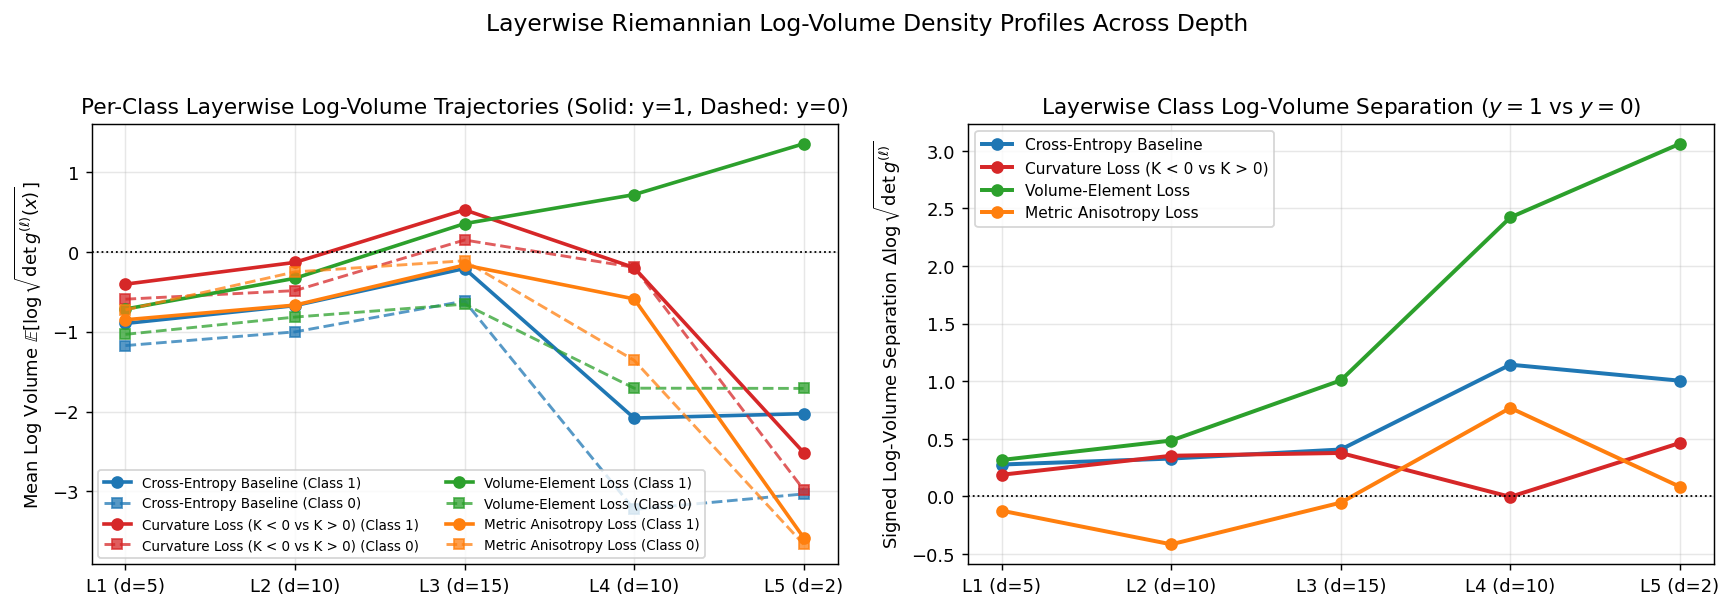

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

print(f"{'Method':<34} | {'L1 Gap':>8} {'L2 Gap':>8} {'L3 Gap':>8} {'L4 Gap':>8} {'L5 Gap':>8}")
print("-" * 86)

for label, (mdl, col) in models_dict.items():
    vol_c0_means, vol_c1_means, vol_gaps = [], [], []
    for l_idx in layers_list:
        g_l = compute_layer_pullback_metric(mdl, X_test, layer_idx=l_idx, metric_mode="euclidean", eps=1e-6).detach()
        log_vol_l = 0.5 * torch.log(torch.clamp(torch.linalg.det(g_l), min=1e-8))
        m0 = log_vol_l[y_test == 0].mean().item()
        m1 = log_vol_l[y_test == 1].mean().item()
        vol_c0_means.append(m0)
        vol_c1_means.append(m1)
        vol_gaps.append(m1 - m0)

    print(f"{label:<34} | {vol_gaps[0]:+8.3f} {vol_gaps[1]:+8.3f} {vol_gaps[2]:+8.3f} {vol_gaps[3]:+8.3f} {vol_gaps[4]:+8.3f}")

    # Panel 1: Per-class mean log-volume profiles (solid = Class 1, dashed = Class 0)
    axes[0].plot(layers_list, vol_c1_means, "o-", lw=2.0, color=col, label=f"{label} (Class 1)")
    axes[0].plot(layers_list, vol_c0_means, "s--", lw=1.6, color=col, alpha=0.75, label=f"{label} (Class 0)")

    # Panel 2: Signed class separation in log-volume density
    axes[1].plot(layers_list, vol_gaps, "o-", lw=2.2, color=col, label=label)

axes[0].axhline(0.0, color="k", lw=1.0, ls=":")
axes[0].set_xticks(layers_list)
axes[0].set_xticklabels([f"L{l} (d={m_ce.layer_dims[l]})" for l in layers_list])
axes[0].set_ylabel("Mean Log Volume $\mathbb{E}[\log\sqrt{\det g^{(\ell)}(x)}]$")
axes[0].set_title("Per-Class Layerwise Log-Volume Trajectories (Solid: y=1, Dashed: y=0)")
axes[0].legend(fontsize=7.5, ncol=2)
axes[0].grid(alpha=0.3)

axes[1].axhline(0.0, color="k", lw=1.0, ls=":")
axes[1].set_xticks(layers_list)
axes[1].set_xticklabels([f"L{l} (d={m_ce.layer_dims[l]})" for l in layers_list])
axes[1].set_ylabel("Signed Log-Volume Separation $\Delta \log\sqrt{\det g^{(\ell)}}$")
axes[1].set_title("Layerwise Class Log-Volume Separation ($y=1$ vs $y=0$)")
axes[1].legend(fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.suptitle("Layerwise Riemannian Log-Volume Density Profiles Across Depth", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 5. Layerwise Metric Anisotropy Profiles ($\log(g^{(\ell)}_{11}/g^{(\ell)}_{22})$ & Spectral Condition Number $\lambda_1^{(\ell)}/\lambda_2^{(\ell)}$)

We now analyze how directional stretching and spectral anisotropy of the pullback metric tensor $g^{(\ell)}_{ij}(x; \theta)$ evolve across layers $\ell \in \{1, 2, 3, 4, 5\}$ under the four training objectives, examining two complementary anisotropy measures:
1. **Directional Metric Polarization Separation**:
   $$\Delta \log\!\left(\frac{g^{(\ell)}_{11}}{g^{(\ell)}_{22}}\right) = \mathbb{E}\!\left[\log\frac{g^{(\ell)}_{11}(x)}{g^{(\ell)}_{22}(x)} \;\Bigg|\; y = 1\right] - \mathbb{E}\!\left[\log\frac{g^{(\ell)}_{11}(x)}{g^{(\ell)}_{22}(x)} \;\Bigg|\; y = 0\right]$$
   which quantifies how strongly each layer polarizes horizontal ($x^1$) versus vertical ($x^2$) metric dilation between Class $1$ and Class $0$.
2. **Coordinate-Invariant Spectral Condition Number (Eigenvalue Anisotropy)**:
   $$\mathbb{E}_{x}\!\left[\log_{10}\!\left(\frac{\lambda_{\max}(g^{(\ell)}(x))}{\lambda_{\min}(g^{(\ell)}(x))}\right)\right]$$
   which measures how strongly each layer compresses tangent vectors along 1D foliation leaves relative to orthogonal directions (**Benfenati & Marta, 2023**).

Method                             | L1 Aniso Gap L3 Aniso Gap L5 Aniso Gap | L5 log10(l1/l2)
----------------------------------------------------------------------------------------------
Cross-Entropy Baseline             |       +0.032       -0.063       -0.256 |           2.285
Curvature Loss (K < 0 vs K > 0)    |       +0.221       +0.360       +0.083 |           1.701
Volume-Element Loss                |       +0.015       -0.109       +0.219 |           1.369
Metric Anisotropy Loss             |       +0.247       +1.290       +1.982 |           3.707


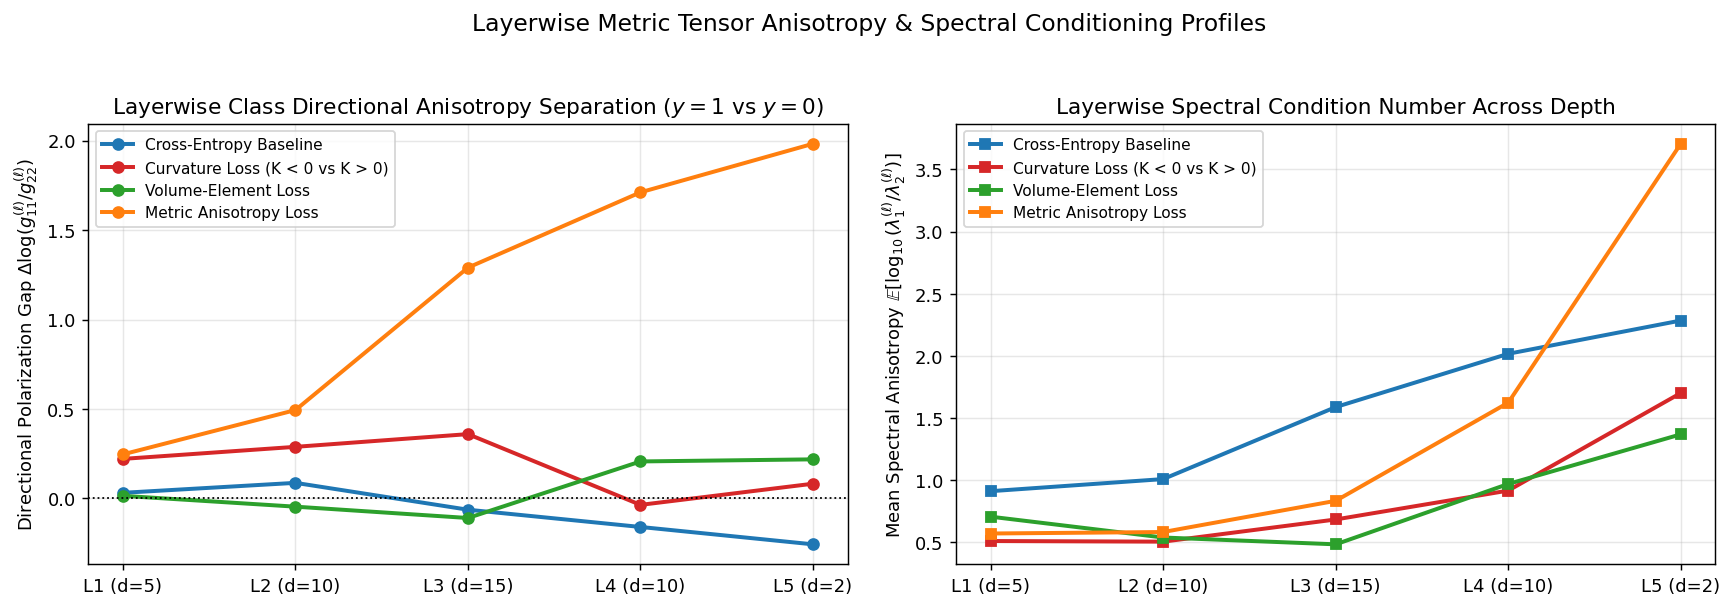

In [6]:
from src.geometry import compute_metric_spectrum

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

print(f"{'Method':<34} | {'L1 Aniso Gap':>12} {'L3 Aniso Gap':>12} {'L5 Aniso Gap':>12} | {'L5 log10(l1/l2)':>15}")
print("-" * 94)

for label, (mdl, col) in models_dict.items():
    aniso_gaps, log_conds = [], []
    for l_idx in layers_list:
        g_graph = compute_layer_pullback_metric(mdl, X_test, layer_idx=l_idx, metric_mode="graph").detach()
        log_ratio = torch.log(torch.clamp(g_graph[:, 0, 0], min=1e-8) / torch.clamp(g_graph[:, 1, 1], min=1e-8))
        gap = (log_ratio[y_test == 1].mean() - log_ratio[y_test == 0].mean()).item()
        aniso_gaps.append(gap)

        g_eucl = compute_layer_pullback_metric(mdl, X_test, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7).detach()
        _, _, cond = compute_metric_spectrum(g_eucl)
        log_conds.append(torch.log10(torch.clamp(cond, min=1.0)).mean().item())

    print(f"{label:<34} | {aniso_gaps[0]:+12.3f} {aniso_gaps[2]:+12.3f} {aniso_gaps[4]:+12.3f} | {log_conds[4]:15.3f}")

    # Panel 1: Layerwise directional anisotropy separation (y=1 vs y=0)
    axes[0].plot(layers_list, aniso_gaps, "o-", lw=2.2, color=col, label=label)

    # Panel 2: Layerwise spectral condition number log10(lambda_1 / lambda_2)
    axes[1].plot(layers_list, log_conds, "s-", lw=2.2, color=col, label=label)

axes[0].axhline(0.0, color="k", lw=1.0, ls=":")
axes[0].set_xticks(layers_list)
axes[0].set_xticklabels([f"L{l} (d={m_ce.layer_dims[l]})" for l in layers_list])
axes[0].set_ylabel("Directional Polarization Gap $\Delta \log(g^{(\ell)}_{11} / g^{(\ell)}_{22})$")
axes[0].set_title("Layerwise Class Directional Anisotropy Separation ($y=1$ vs $y=0$)")
axes[0].legend(fontsize=8.5)
axes[0].grid(alpha=0.3)

axes[1].set_xticks(layers_list)
axes[1].set_xticklabels([f"L{l} (d={m_ce.layer_dims[l]})" for l in layers_list])
axes[1].set_ylabel("Mean Spectral Anisotropy $\mathbb{E}[\log_{10}(\lambda_1^{(\ell)} / \lambda_2^{(\ell)})]$")
axes[1].set_title("Layerwise Spectral Condition Number Across Depth")
axes[1].legend(fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.suptitle("Layerwise Metric Tensor Anisotropy & Spectral Conditioning Profiles", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 6. Computational and Memory Cost Comparison Across the Four Methods

A critical practical distinction between the four training objectives is their **differential order** and resulting automatic differentiation complexity:

| Method | Spatial Derivative Order | Parameter Gradient Order | Autodiff Mechanism |
| :--- | :---: | :---: | :--- |
| **1. Cross-Entropy Baseline** | $0$th-order ($z(x; \theta)$) | **1st-order** ($\nabla_\theta z$) | Standard reverse-mode backprop |
| **2. Gaussian Curvature Loss** | $2$nd-order ($\partial_l\partial_k g_{ij}(x; \theta)$) | **3rd-order** ($\nabla_\theta \partial_x^2 g_{ij}$) | Nested `vmap(jacrev(jacrev(jacrev)))` + backward |
| **3. Volume-Element Loss** | $1$st-order ($J(x; \theta) = \partial_x z$) | **2nd-order** ($\nabla_\theta \partial_x z$) | `vmap(jacrev)` + backward |
| **4. Metric Anisotropy Loss** | $1$st-order ($J(x; \theta) = \partial_x z$) | **2nd-order** ($\nabla_\theta \partial_x z$) | `vmap(jacrev)` + backward |

Below we profile each method on the `[2 -> 5 -> 10 -> 15 -> 10 -> 2]` MLP ($N = 220$ training points) using `torch.profiler` (`profile_memory=True`) and autograd computation graph traversal to compare:
1. **Step Latency (`ms / step`)** for a full forward + backward pass.
2. **CPU Tensor Memory Allocated (`MB / step`)** during forward + backward execution.
3. **Autograd Computation Graph Size (`# grad_fn nodes`)** retained in memory for backpropagation.

Method                             Latency (ms/step)    Memory (MB/step)     Autograd Nodes   Test Acc  
------------------------------------------------------------------------------------------------------
Cross-Entropy (1st-Order)          0.83                 0.51                 26               100.00%
Volume-Element (2nd-Order)         3.83                 3.47                 107              100.00%
Metric Anisotropy (2nd-Order)      3.78                 3.58                 114              100.00%
Gaussian Curvature (3rd-Order)     49.22                324.81               1036              96.67%


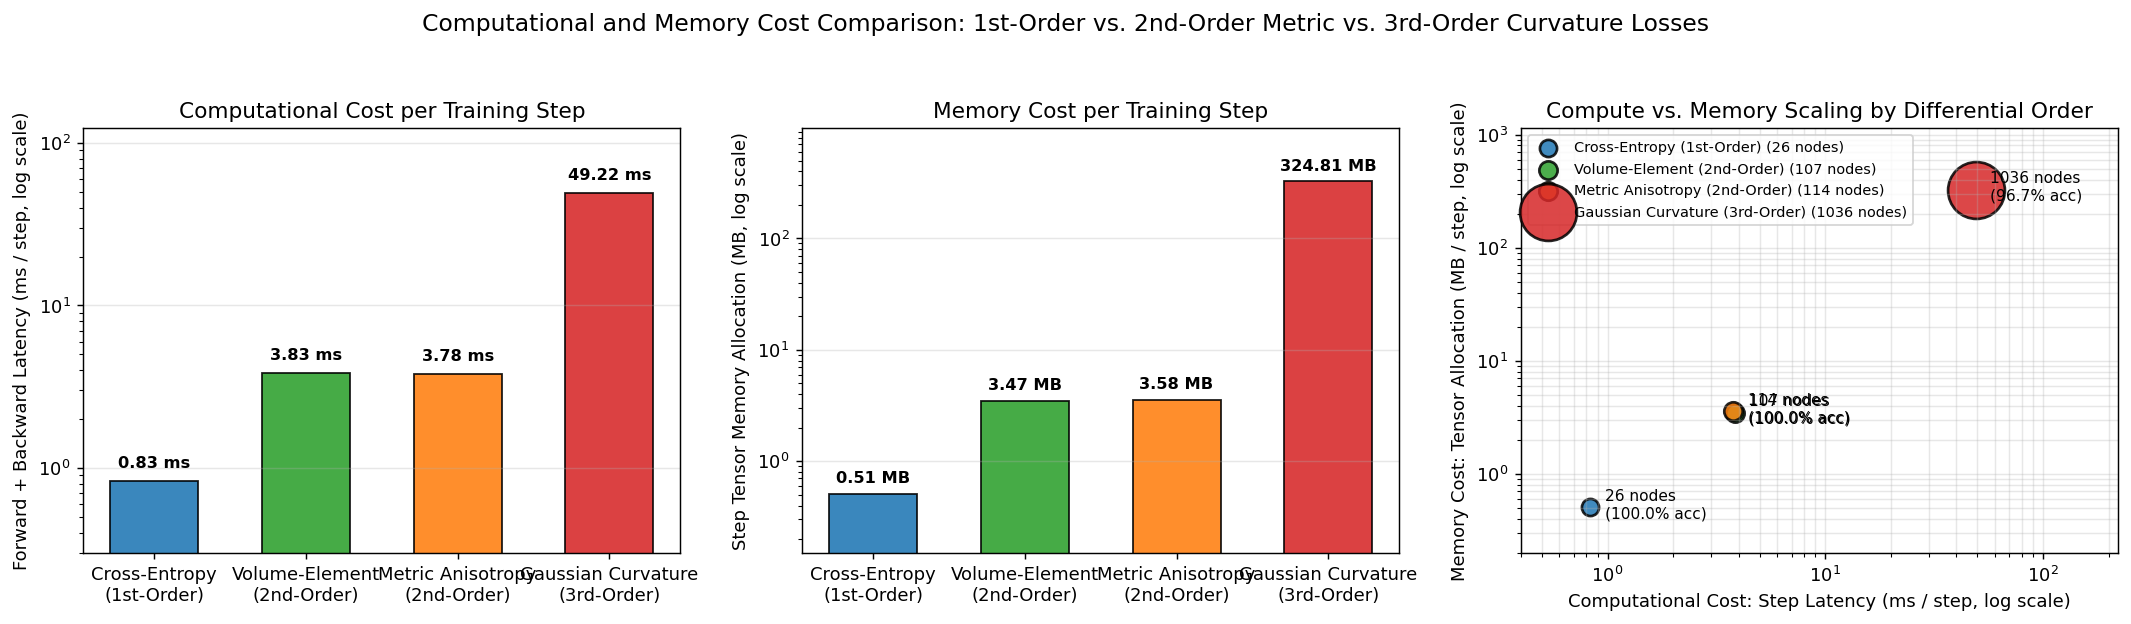

In [7]:
import time
from torch.profiler import profile, ProfilerActivity

def count_autograd_graph_nodes(grad_fn) -> int:
    visited = set()
    stack = [grad_fn]
    while stack:
        node = stack.pop()
        if node is None or node in visited:
            continue
        visited.add(node)
        for next_node, _ in getattr(node, "next_functions", []):
            stack.append(next_node)
    return len(visited)

probe_net = MoonsMLP(activation="tanh", seed=7)
ce_loss_fn = nn.CrossEntropyLoss()

def step_loss_ce():
    return ce_loss_fn(probe_net(X_train), y_train)

def step_loss_curv():
    params = dict(probe_net.named_parameters())
    g5 = compute_layer_geometry(probe_net, X_train, layer_idx=5, metric_mode="graph", params=params)
    loss, _ = curvature_margin_loss(g5["K"], y_train, g5["g"], margin=0.40)
    return loss

def step_loss_vol():
    params = dict(probe_net.named_parameters())
    g5 = compute_layer_pullback_metric(probe_net, X_train, layer_idx=5, metric_mode="euclidean", eps=1e-6, params=params)
    loss, _ = volume_contrastive_loss(g5, y_train, margin=0.60)
    return loss

def step_loss_aniso():
    params = dict(probe_net.named_parameters())
    g5 = compute_layer_pullback_metric(probe_net, X_train, layer_idx=5, metric_mode="graph", params=params)
    loss, _ = anisotropy_margin_loss(g5, y_train, margin=0.45)
    return loss

def benchmark_method(loss_builder, n_repeats: int = 15):
    # Warmup & count autograd graph nodes
    probe_net.zero_grad()
    loss_val = loss_builder()
    graph_nodes = count_autograd_graph_nodes(loss_val.grad_fn)
    loss_val.backward()

    # Profile CPU memory allocation during a single forward + backward step
    with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
        probe_net.zero_grad()
        l_p = loss_builder()
        l_p.backward()
    mem_mb = sum(e.cpu_memory_usage for e in prof.key_averages() if e.cpu_memory_usage > 0) / (1024.0 * 1024.0)

    # Measure forward + backward step latency
    t0 = time.perf_counter()
    for _ in range(n_repeats):
        probe_net.zero_grad()
        l_t = loss_builder()
        l_t.backward()
    step_ms = (time.perf_counter() - t0) * 1000.0 / n_repeats
    return step_ms, mem_mb, graph_nodes

method_specs = [
    ("Cross-Entropy\n(1st-Order)", step_loss_ce, ce_te_acc * 100.0, "#1f77b4"),
    ("Volume-Element\n(2nd-Order)", step_loss_vol, vol_te_acc * 100.0, "#2ca02c"),
    ("Metric Anisotropy\n(2nd-Order)", step_loss_aniso, aniso_te_acc * 100.0, "#ff7f0e"),
    ("Gaussian Curvature\n(3rd-Order)", step_loss_curv, curv_te_acc * 100.0, "#d62728"),
]

results = []
for name, fn, acc_pct, col in method_specs:
    ms, mb, nodes = benchmark_method(fn)
    results.append({"name": name, "clean_name": name.replace("\n", " "), "ms": ms, "mb": mb, "nodes": nodes, "acc": acc_pct, "color": col})

print(f"{'Method':<34} {'Latency (ms/step)':<20} {'Memory (MB/step)':<20} {'Autograd Nodes':<16} {'Test Acc':<10}")
print("-" * 102)
for r in results:
    print(f"{r['clean_name']:<34} {r['ms']:<20.2f} {r['mb']:<20.2f} {r['nodes']:<16d} {r['acc']:6.2f}%")

names = [r["name"] for r in results]
colors = [r["color"] for r in results]
latencies = [r["ms"] for r in results]
memories = [r["mb"] for r in results]
node_counts = [r["nodes"] for r in results]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

# Panel 1: Step Latency (ms/step)
bars0 = axes[0].bar(names, latencies, color=colors, edgecolor="k", alpha=0.88, width=0.58)
axes[0].set_yscale("log")
axes[0].set_ylabel("Forward + Backward Latency (ms / step, log scale)")
axes[0].set_title("Computational Cost per Training Step")
axes[0].grid(axis="y", alpha=0.3)
for b, val in zip(bars0, latencies):
    axes[0].text(b.get_x() + b.get_width() / 2, val * 1.15, f"{val:.2f} ms", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0.3, max(latencies) * 2.5)

# Panel 2: Memory Footprint (MB/step)
bars1 = axes[1].bar(names, memories, color=colors, edgecolor="k", alpha=0.88, width=0.58)
axes[1].set_yscale("log")
axes[1].set_ylabel("Step Tensor Memory Allocation (MB, log scale)")
axes[1].set_title("Memory Cost per Training Step")
axes[1].grid(axis="y", alpha=0.3)
for b, val in zip(bars1, memories):
    axes[1].text(b.get_x() + b.get_width() / 2, val * 1.18, f"{val:.2f} MB", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_ylim(0.15, max(memories) * 3.0)

# Panel 3: Autograd Graph Nodes vs. Latency & Memory Bubble Plot
for r in results:
    bubble_size = max(np.sqrt(r["mb"]) * 55.0, 90.0)
    axes[2].scatter(r["ms"], r["mb"], s=bubble_size, color=r["color"], edgecolors="k", linewidth=1.5, alpha=0.85, label=f"{r['clean_name']} ({r['nodes']} nodes)")
    axes[2].annotate(f"{r['nodes']} nodes\n({r['acc']:.1f}% acc)", (r["ms"], r["mb"]), textcoords="offset points", xytext=(8, -6), fontsize=8.5)

axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("Computational Cost: Step Latency (ms / step, log scale)")
axes[2].set_ylabel("Memory Cost: Tensor Allocation (MB / step, log scale)")
axes[2].set_title("Compute vs. Memory Scaling by Differential Order")
axes[2].set_xlim(0.4, max(latencies) * 4.5)
axes[2].set_ylim(0.2, max(memories) * 3.5)
axes[2].grid(alpha=0.3, which="both")
axes[2].legend(fontsize=8, loc="upper left")

plt.suptitle("Computational and Memory Cost Comparison: 1st-Order vs. 2nd-Order Metric vs. 3rd-Order Curvature Losses", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

## 7. $3 \times 4$ Cross-Evaluation Matrix of Final-Layer Geometric Fields Across All Experiments

Finally, we evaluate **all three differential-geometric measures** at the final layer ($\ell = 5$) across **all four trained networks** in the 2D input space $(x^1, x^2)$:
- **Rows (Geometric Measures at Layer $\ell = 5$)**:
  1. **Row 1 — Gaussian Curvature**: $\operatorname{arcsinh}\!\big(K^{(5)}(x)\big)$ (Graph metric $\tilde{g}^{(5)} = I_2 + (J^{(5)})^T J^{(5)}$; $0 = \text{flat}$).
  2. **Row 2 — Log Volume Density**: $\log\sqrt{\det g^{(5)}(x)}$ (Euclidean pullback $g^{(5)} = (J^{(5)})^T J^{(5)}$; $0 = \text{equiareal}$).
  3. **Row 3 — Metric Anisotropy**: $\log\!\big(g^{(5)}_{11}(x) / g^{(5)}_{22}(x)\big)$ (Directional metric ratio; $0 = \text{isotropic } g_{11}=g_{22}$).
- **Columns (Training Experiments)**:
  1. **Column 1**: Cross-Entropy Baseline
  2. **Column 2**: Curvature Margin Loss ($K < 0$ vs. $K > 0$)
  3. **Column 3**: Volume-Element Loss ($\log\sqrt{\det g} < 0$ vs. $> 0$)
  4. **Column 4**: Metric Anisotropy Loss ($\log(g_{11}/g_{22}) < 0$ vs. $> 0$)

All plots use the symmetric `RdBu_r` colormap centered at **$0.0$ (white)**, with the zero-level contour ($0.0$) drawn in black.

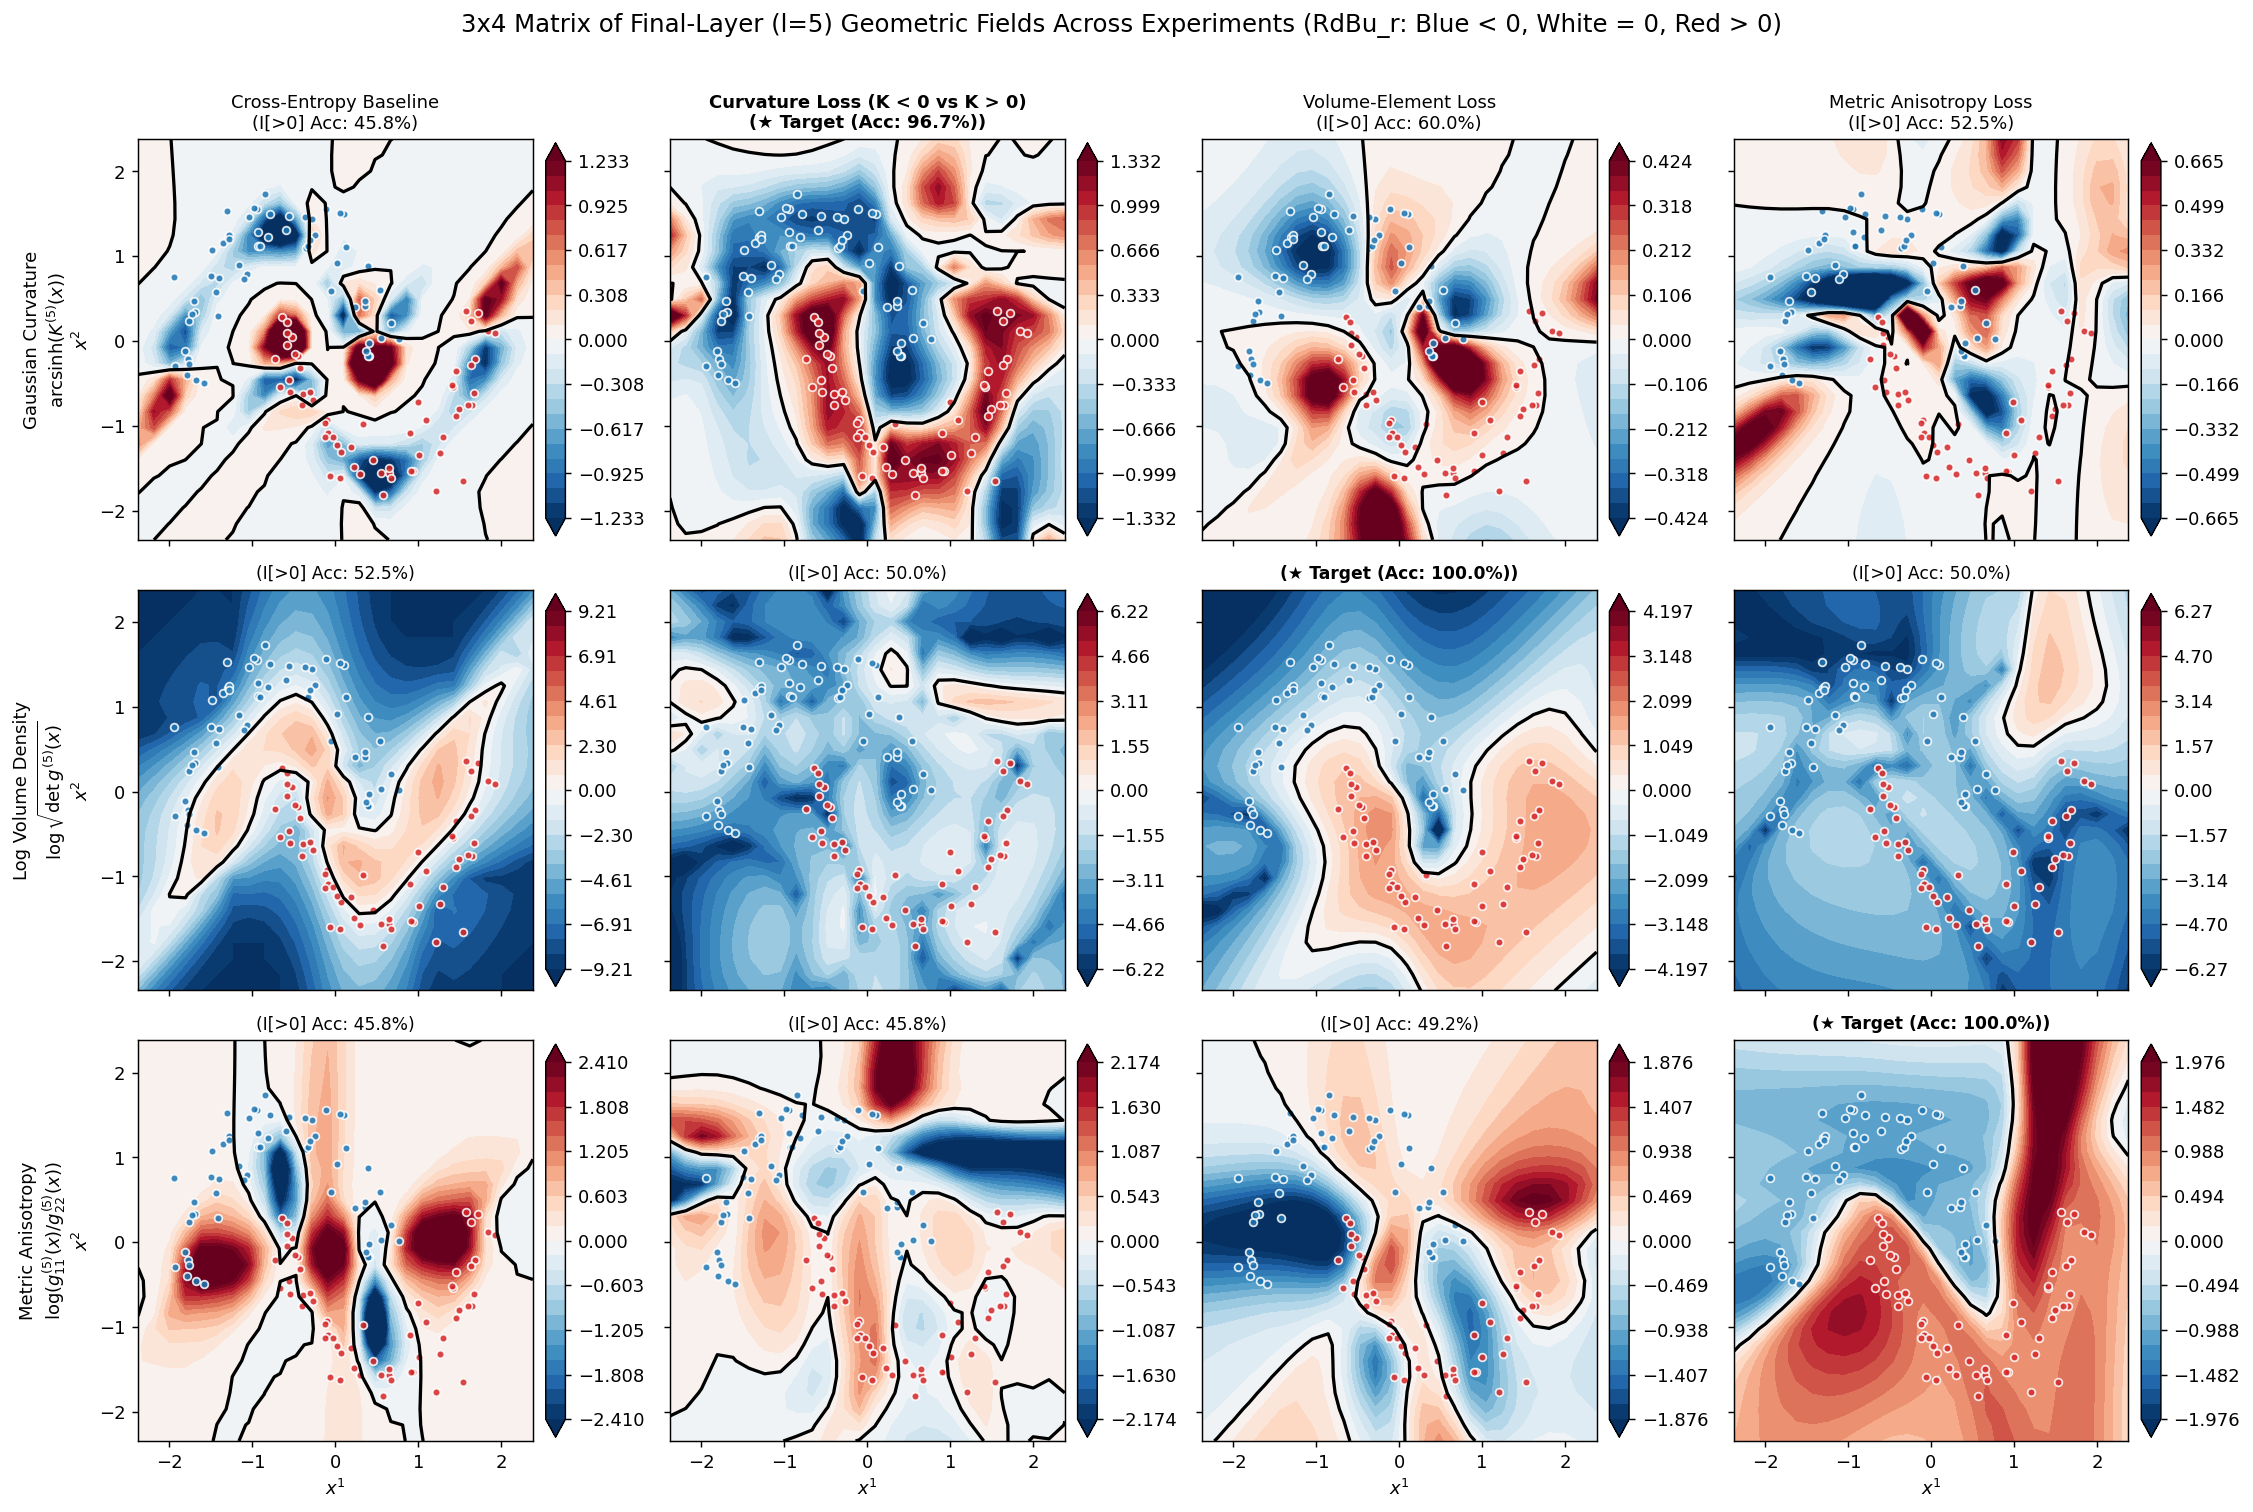

In [8]:
from matplotlib.colors import TwoSlopeNorm

exp_columns = [
    ("Cross-Entropy Baseline", m_ce),
    ("Curvature Loss (K < 0 vs K > 0)", m_curv),
    ("Volume-Element Loss", m_vol),
    ("Metric Anisotropy Loss", m_aniso),
]

row_labels = [
    "Gaussian Curvature\n$\mathrm{arcsinh}(K^{(5)}(x))$",
    "Log Volume Density\n$\log\sqrt{\det g^{(5)}(x)}$",
    "Metric Anisotropy\n$\log(g^{(5)}_{11}(x) / g^{(5)}_{22}(x))$",
]

def evaluate_final_layer_fields(mdl: MoonsMLP, pts: torch.Tensor):
    # 1. Gaussian curvature K^(5) via Graph metric
    geom_graph = compute_layer_geometry(mdl, pts, layer_idx=5, metric_mode="graph")
    curv_field = np.arcsinh(geom_graph["K"].detach().numpy())

    # 2. Log volume density log sqrt(det g^(5)) via Euclidean pullback
    g_eucl = compute_layer_pullback_metric(mdl, pts, layer_idx=5, metric_mode="euclidean", eps=1e-6)
    log_vol_field = (0.5 * torch.log(torch.clamp(torch.linalg.det(g_eucl), min=1e-8))).detach().numpy()

    # 3. Metric anisotropy log(g_11 / g_22) via Graph metric
    g_gr = geom_graph["g"].detach()
    aniso_field = torch.log(torch.clamp(g_gr[:, 0, 0], min=1e-8) / torch.clamp(g_gr[:, 1, 1], min=1e-8)).numpy()

    return [curv_field, log_vol_field, aniso_field]

grid_matrix = [[None for _ in range(4)] for _ in range(3)]
test_acc_matrix = [[0.0 for _ in range(4)] for _ in range(3)]
y_te_np = y_test.numpy()

for col_idx, (_, mdl) in enumerate(exp_columns):
    grid_fields = evaluate_final_layer_fields(mdl, grid_pts)
    test_fields = evaluate_final_layer_fields(mdl, X_test)
    for row_idx in range(3):
        grid_matrix[row_idx][col_idx] = grid_fields[row_idx].reshape(xx.shape)
        preds_pos = (test_fields[row_idx] > 0.0).astype(int)
        test_acc_matrix[row_idx][col_idx] = float((preds_pos == y_te_np).mean() * 100.0)

fig, axes = plt.subplots(3, 4, figsize=(17.5, 11.5), sharex=True, sharey=True)

for row_idx in range(3):
    for col_idx, (col_title, _) in enumerate(exp_columns):
        ax = axes[row_idx, col_idx]
        fld = grid_matrix[row_idx][col_idx]
        vm = float(max(np.percentile(np.abs(fld), 96), 0.25))
        levels = np.linspace(-vm, vm, 25)
        norm = TwoSlopeNorm(vmin=-vm, vcenter=0.0, vmax=vm)

        im = ax.contourf(xx, yy, fld, levels=levels, cmap="RdBu_r", norm=norm, extend="both")
        if fld.min() < 0.0 < fld.max():
            ax.contour(xx, yy, fld, levels=[0.0], colors="k", linewidths=1.8)

        ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", edgecolors="w", s=18, alpha=0.85)
        ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", edgecolors="w", s=18, alpha=0.85)

        acc_val = test_acc_matrix[row_idx][col_idx]
        is_target_pair = (row_idx == 0 and col_idx == 1) or (row_idx == 1 and col_idx == 2) or (row_idx == 2 and col_idx == 3)
        tag = f"★ Target (Acc: {acc_val:.1f}%)" if is_target_pair else f"I[>0] Acc: {acc_val:.1f}%"

        if row_idx == 0:
            ax.set_title(f"{col_title}\n({tag})", fontsize=10, fontweight="bold" if is_target_pair else "normal")
        else:
            ax.set_title(f"({tag})", fontsize=9.5, fontweight="bold" if is_target_pair else "normal")

        if col_idx == 0:
            ax.set_ylabel(f"{row_labels[row_idx]}\n$x^2$", fontsize=10)
        if row_idx == 2:
            ax.set_xlabel("$x^1$", fontsize=10)

        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

plt.suptitle(
    "3x4 Matrix of Final-Layer (l=5) Geometric Fields Across Experiments (RdBu_r: Blue < 0, White = 0, Red > 0)",
    y=1.01,
    fontsize=13.5,
)
plt.tight_layout()
plt.show()